# Defleksi Cahaya di Ruang-waktu Kerr–de Sitter

Lintasan foton diintegrasikan dengan RK4 pada persamaan Hamilton $H = \tfrac12 g^{\mu\nu} p_\mu p_\nu$ untuk beberapa nilai konstanta kosmologi $\Lambda$.
Kode fisika ada di package `kerr_ds` (folder `src/kerr_ds/`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from kerr_ds import (
    kerr_horizon_radius,
    run_lambda_sweep,
    plot_trajectories,
    plot_hamiltonian_vs_step,
    plot_hamiltonian_vs_r,
)

## Parameter

In [2]:
# Parameter Fisika
M = 1.0
a = -0.99
lambdas = [0.0, -1e-8, -5e-8, -1e-7, -5e-7, -1e-6, -5e-6]

# Kondisi Awal Cahaya
r0 = 500.0
theta0 = np.pi / 2
phi0 = 0.0

# Parameter Cahaya
E = 1.0
b = 7
L_ang = b * E

# Parameter Integrasi
dtau = 0.05
max_steps = 30000

# Radius Event Horizon untuk visualisasi (Kerr approx)
rh = kerr_horizon_radius(M, a)

## Simulasi

Hamiltonian diturunkan secara simbolik **sekali** (run pertama ±2 menit, berikutnya dimuat dari cache `~/.cache/kerr_ds/`), lalu setiap nilai $\Lambda$ diintegrasikan secara paralel.

In [3]:
results = run_lambda_sweep(M, a, lambdas, r0, theta0, phi0, E, L_ang, rh,
                           dtau=dtau, max_steps=max_steps)

a          | Lambda     | Deflection (deg)     | Status
-------------------------------------------------------


-0.99      | 0.0        | 244.4703             | Steps: 20374


-0.99      | -1e-08     | 244.4689             | Steps: 20374


-0.99      | -5e-08     | 244.4637             | Steps: 20374


-0.99      | -1e-07     | 244.4571             | Steps: 20374


-0.99      | -5e-07     | 244.4042             | Steps: 20374


-0.99      | -1e-06     | 244.3381             | Steps: 20374


-0.99      | -5e-06     | 243.8062             | Steps: 20374


## Lintasan foton

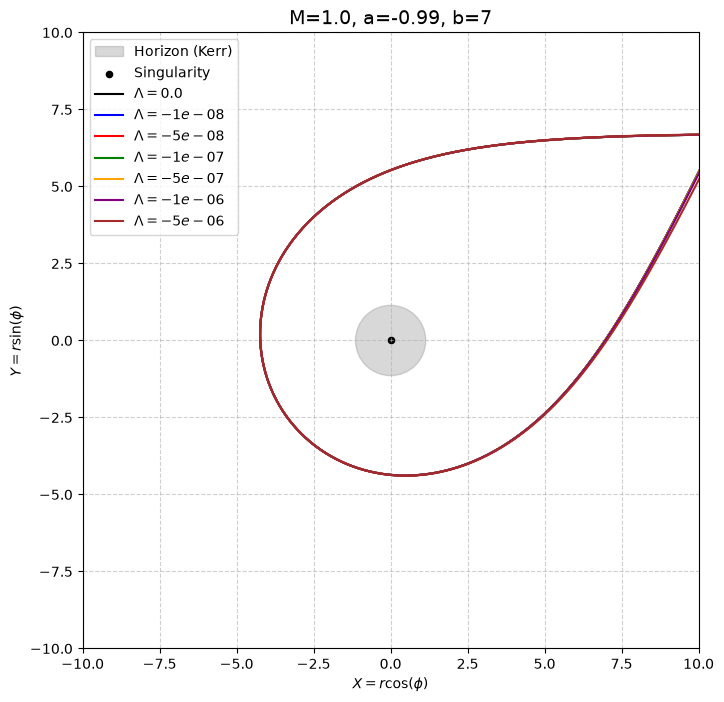

In [4]:
plot_trajectories(results, M, a, b, rh)
plt.show()

## Validasi konservasi Hamiltonian (trayektori terakhir)

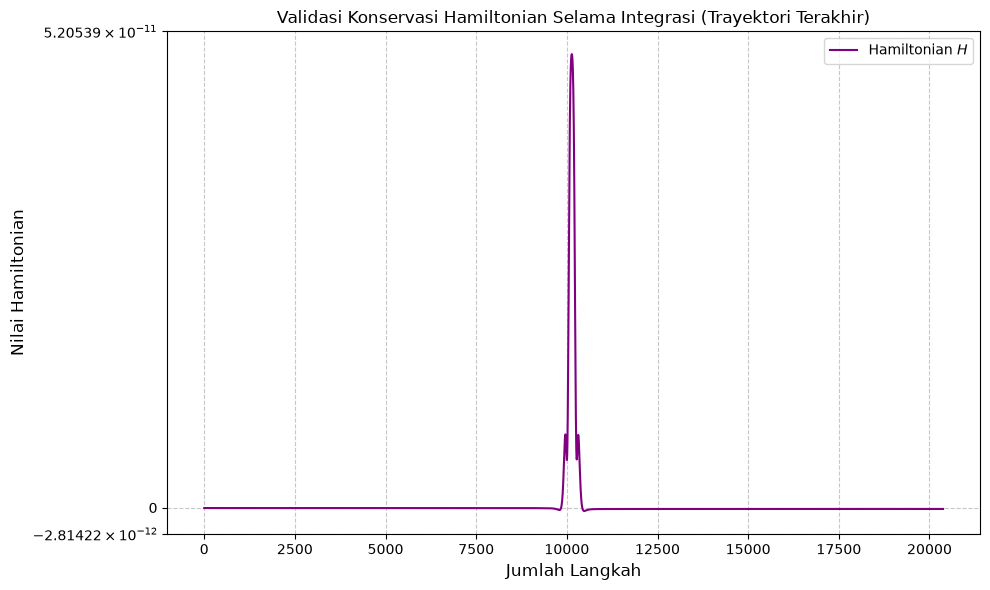

In [5]:
last = results[-1]

plot_hamiltonian_vs_step(last)
plt.show()

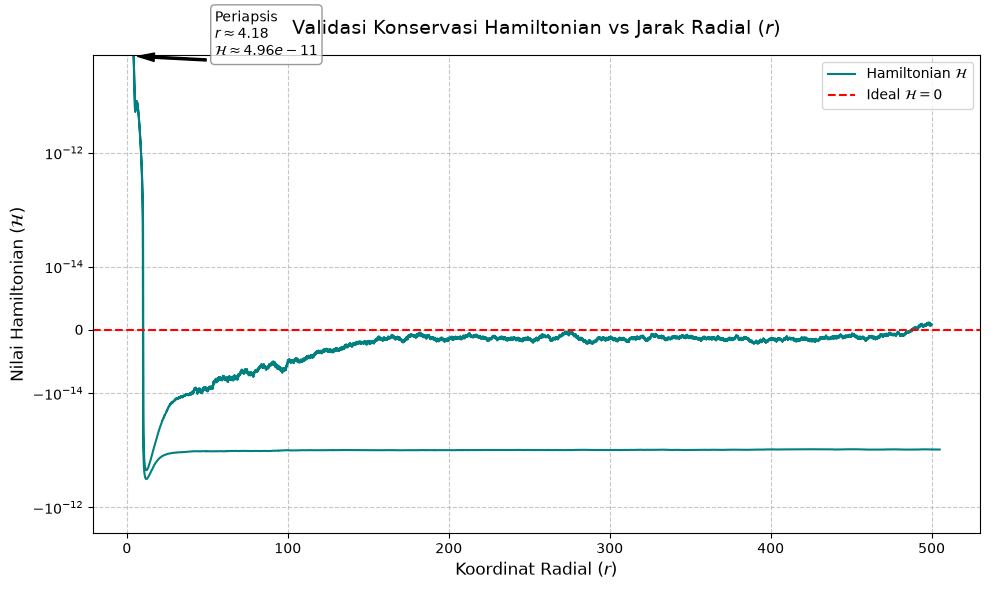

In [6]:
plot_hamiltonian_vs_r(last)
plt.show()